# 01 — Sanity checks on the ingested data

Quick checks on `data/processed/*.parquet` (produced by `f1pred-ingest`):
coverage, pole → win conversion by regulation era, and 2026 winners so far.

Two definitions of *pole*: **grid = 1** (actual starting position, after penalties) and **qualifying P1**. Races with an unpublished grid are excluded from the grid-based rate.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path('..') / 'data' / 'processed'
t = {p.stem: pd.read_parquet(p) for p in DATA.glob('*.parquet')}
report = json.loads((DATA / 'ingest_report.json').read_text(encoding='utf-8'))
print('generated_at:', report['generated_at'], '| latest round:', report['latest_round'])
pd.Series(report['row_counts'], name='rows').to_frame()

generated_at: 2026-11-08T22:54:45.376066+00:00 | latest round: {'season': 2026, 'round': 20, 'race_name': 'Brazilian Grand Prix', 'date': '2026-11-08'}


,rows
races,275
results,5545
qualifying,5524
sprint_results,612
driver_standings,5820
constructor_standings,2779
drivers,65
constructors,22
circuits,33


## Coverage per season

In [2]:
races, res, q = t['races'], t['results'], t['qualifying']
cov = pd.DataFrame({
    'scheduled': races.groupby('season').size(),
    'with_results': res.groupby('season')['round'].nunique(),
    'with_quali': q.groupby('season')['round'].nunique(),
    'sprints': t['sprint_results'].groupby('season')['round'].nunique()
    if not t['sprint_results'].empty else 0,
    'standings_rounds': t['driver_standings'].groupby('season')['round'].nunique(),
}).fillna(0).astype(int)
cov

,scheduled,with_results,with_quali,sprints,standings_rounds
season,,,,,
2014,19,19,19,0,19
2015,19,19,19,0,19
2016,21,21,21,0,21
2017,20,20,20,0,20
2018,21,21,21,0,21
2019,21,21,21,0,21
2020,17,17,17,0,17
2021,22,22,22,3,22
2022,22,22,22,3,22


## Pole → win conversion by era

In [3]:
def era(season):
    return '2014–2021' if season <= 2021 else ('2022–2025' if season <= 2025 else '2026')

winners = res[res['position'] == 1][['season', 'round', 'driver_id', 'constructor_id', 'grid']]
qpole = q[q['position'] == 1][['season', 'round', 'driver_id']].rename(
    columns={'driver_id': 'quali_pole'})
w = winners.merge(qpole, on=['season', 'round'], how='left')
w['era'] = w['season'].map(era)
w['won_from_grid1'] = (w['grid'] == 1).where(w['grid'].notna())
w['won_from_quali_pole'] = (w['driver_id'] == w['quali_pole']).where(w['quali_pole'].notna())

summary = w.groupby('era').agg(
    races=('round', 'size'),
    races_with_grid=('won_from_grid1', 'count'),
    pole_win_pct_grid=('won_from_grid1', 'mean'),
    pole_win_pct_quali=('won_from_quali_pole', 'mean'),
)
summary[['pole_win_pct_grid', 'pole_win_pct_quali']] *= 100
summary.round(1)

,races,races_with_grid,pole_win_pct_grid,pole_win_pct_quali
era,,,,
2014–2021,160,160,52.5,53.1
2022–2025,92,92,55.4,57.6
2026,20,19,68.4,70.0


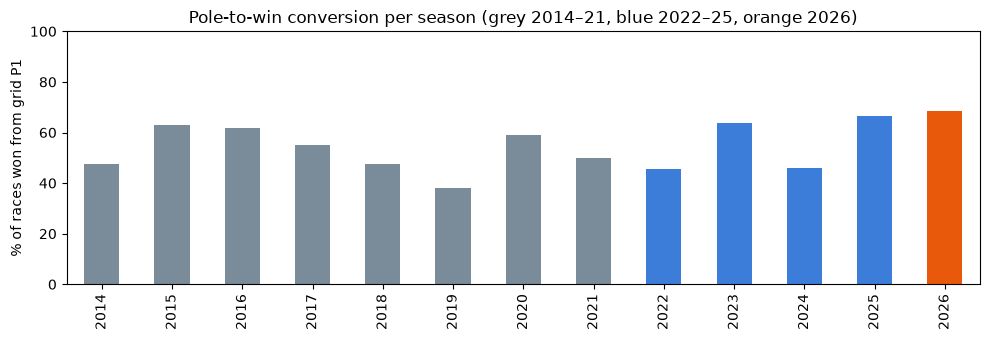

In [4]:
per_season = w.groupby('season')['won_from_grid1'].mean() * 100
colors = ['#7a8b99' if s <= 2021 else '#3b7dd8' if s <= 2025 else '#e8590c'
          for s in per_season.index]
ax = per_season.plot.bar(color=colors, figsize=(10, 3.5))
ax.set_ylabel('% of races won from grid P1')
ax.set_xlabel('')
ax.set_title('Pole-to-win conversion per season (grey 2014–21, blue 2022–25, orange 2026)')
ax.set_ylim(0, 100)
plt.tight_layout()

## 2026 winners so far

In [5]:
d = t['drivers'].set_index('driver_id')
c = t['constructors'].set_index('constructor_id')
w26 = (w[w['season'] == 2026]
       .merge(races[['season', 'round', 'race_name', 'race_date']], on=['season', 'round'])
       .assign(winner=lambda x: x['driver_id'].map(d['family_name']),
               team=lambda x: x['constructor_id'].map(c['name']))
       [['round', 'race_name', 'race_date', 'winner', 'team', 'grid', 'quali_pole']])
w26

,round,race_name,race_date,winner,team,grid,quali_pole
0,1,Australian Grand Prix,2026-03-08,Russell,Mercedes,1,russell
1,2,Chinese Grand Prix,2026-03-15,Antonelli,Mercedes,1,antonelli
2,3,Japanese Grand Prix,2026-03-29,Antonelli,Mercedes,1,antonelli
3,4,Miami Grand Prix,2026-05-03,Antonelli,Mercedes,1,antonelli
4,5,Canadian Grand Prix,2026-05-24,Antonelli,Mercedes,2,russell
5,6,Monaco Grand Prix,2026-06-07,Antonelli,Mercedes,1,antonelli
6,7,Barcelona Grand Prix,2026-06-14,Hamilton,Ferrari,2,russell
7,8,Austrian Grand Prix,2026-06-28,Russell,Mercedes,1,russell
8,9,British Grand Prix,2026-07-05,Leclerc,Ferrari,2,antonelli
9,10,Belgian Grand Prix,2026-07-19,Antonelli,Mercedes,1,antonelli


In [6]:
w26.groupby(['winner', 'team']).size().rename('wins').sort_values(ascending=False).reset_index()

,winner,team,wins
0,Antonelli,Mercedes,9
1,Norris,McLaren,3
2,Verstappen,Red Bull,3
3,Russell,Mercedes,3
4,Hamilton,Ferrari,1
5,Leclerc,Ferrari,1


In [7]:
w26['team'].value_counts().rename('wins').reset_index()

,team,wins
0,Mercedes,12
1,McLaren,3
2,Red Bull,3
3,Ferrari,2


## Gaps reported by the ingestion

In [8]:
gaps = pd.DataFrame(report['gaps'])
gaps if not gaps.empty else 'no gaps reported'

,kind,season,round,rows,of
0,fastest_lap_missing,2021,12,NaN,NaN
1,grid_null,2026,20,22.0,22.0
2,fastest_lap_missing,2026,20,NaN,NaN
